# گزارش مینی پروژه MLP
این نوت‌بوک شامل کدهای اجرایی، پاسخ به پرسش‌های نظری و تحلیل‌های عملی مربوط به پروژه است. ساختار، بر اساس بخش‌بندی خواسته شده مرتب شده است.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from keras.models import Sequential
from keras.layers import Dense
from keras.optimizers import Adam, SGD
from keras.callbacks import EarlyStopping


### بخش اول: دریافت و بررسی داده

**پاسخ‌های نظری:**
- **شکل آرایه‌ها و معنای ابعاد:** پیش از تقسیم‌بندی، آرایه ورودی $X$ دارای شکل (100, 3) و آرایه خروجی $U$ دارای شکل (100, 1) است. بُعد اول (عدد ۱۰۰) نشان‌دهنده تعداد سطرها یا همان نمونه‌های داده (Samples) است. بُعد دوم در $X$ (عدد ۳) تعداد ویژگی‌های ورودی (متغیرهای X و Y و Z) و در $U$ (عدد ۱) تعداد متغیر هدف را نشان می‌دهد.


In [2]:
# %% 1. Load and Inspect Data
filename = 'nonlinear_mlp_data_seed_17772130.csv'
seed = 17772130
print(f"Data File: {filename}")
print(f"Group Seed: {seed}\n")
data = pd.read_csv(filename)

# Make all column headers uppercase to match the script's variables
data.columns = [col.upper() for col in data.columns] 

print('--- First 5 rows of data ---')
print(data.head(), '\n')

# Report rows, columns, data types, and missing values
print('--- Dataset Info (Rows, Columns, Data Types) ---')
print(data.info(), '\n')

print('--- Missing Values ---')
print(data.isna().sum(), '\n')

# Check for Duplicate Rows
num_total_rows = len(data)
num_unique_rows = len(data.drop_duplicates())
num_duplicates = num_total_rows - num_unique_rows
print(f'Number of duplicate rows: {num_duplicates}')

if num_duplicates > 0:
    print('Duplicate rows exist in the dataset.')
else:
    print('No duplicate rows found.')

# Check for Anomalous/Outlier Values (Z-score method)
z_scores = np.abs(stats.zscore(data))
outlier_rows, outlier_cols = np.where(z_scores > 3)
print(f'\nNumber of anomalous values (|Z-score| > 3): {len(outlier_rows)}')

if len(outlier_rows) > 0:
    print('Anomalous values detected at (row, col):')
    for r, c in zip(outlier_rows, outlier_cols):
        print(f'({r}, {c})')
else:
    print('No extreme anomalous values found based on Z-score method.')


Data File: nonlinear_mlp_data_seed_17772130.csv
Group Seed: 17772130

--- First 5 rows of data ---
          X         Y         Z          U
0  2.978583  1.019280 -0.098887  21.726966
1  2.731965  1.904417  2.758820  24.238777
2  2.544557  2.481054 -0.377376  18.969530
3  1.498618  0.578681  1.682780   6.434393
4  2.320549  2.617634  5.028241  24.259863 

--- Dataset Info (Rows, Columns, Data Types) ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       100 non-null    float64
 1   Y       100 non-null    float64
 2   Z       100 non-null    float64
 3   U       100 non-null    float64
dtypes: float64(4)
memory usage: 3.3 KB
None 

--- Missing Values ---
X    0
Y    0
Z    0
U    0
dtype: int64 

Number of duplicate rows: 0
No duplicate rows found.

Number of anomalous values (|Z-score| > 3): 0
No extreme anomalous values found based on Z-score met

### بخش دوم: تحلیل اکتشافی و بصری‌سازی

**پاسخ‌های نظری:**
- **روند نمودارها و شواهد:** با توجه به تصویر Data Exploration.png، متغیر X یک روند کاملاً صعودی (افزایشی) و خمیده با خروجی U دارد که نشان‌دهنده یک رابطه غیرخطی است. نمودارهای U در برابر Y و Z نقاطی پراکنده را نشان می‌دهند و روند روشنی در نمودار دوبعدی آن‌ها مشخص نیست. انحنای مشهود در نمودار U در برابر X، قوی‌ترین شاهد بصری برای وجود رابطه غیرخطی در این مجموعه داده است.
- **همبستگی در برابر رابطه علّی:** مشاهده روند یا همبستگی میان دو متغیر در یک نمودار لزوماً به معنای وجود رابطه علت و معلولی نیست، زیرا این روند می‌تواند ناشی از تصادف، متغیرهای پنهان (Confounding Variables)، یا نویز باشد.



--- Data Summary ---
                X           Y           Z           U
count  100.000000  100.000000  100.000000  100.000000
mean     1.988920    1.996437    2.007467   17.383118
std      0.889276    0.867038    2.343986    8.855880
min      0.516018    0.522296   -1.997022    2.176807
25%      1.261381    1.228285    0.000850   10.488246
50%      1.986623    1.971143    2.010391   15.699896
75%      2.794401    2.745820    3.957883   24.290632
max      3.498778    3.494687    5.873264   38.138067 



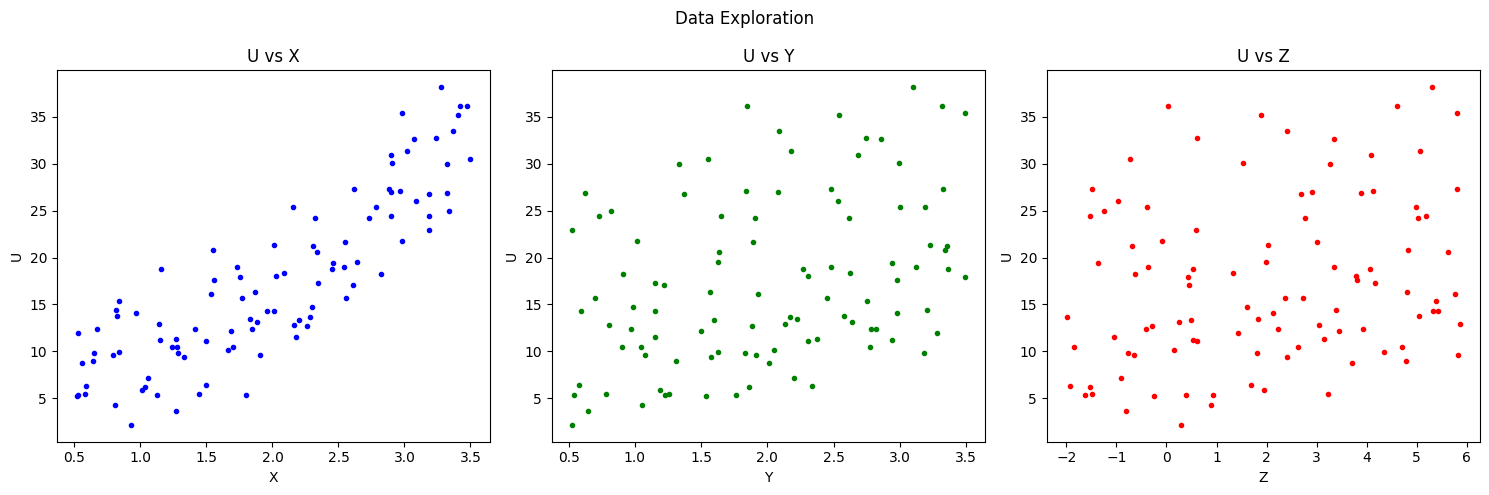

In [3]:
# %% 2. Data Exploration (Scatter Plots)
print('\n--- Data Summary ---')
print(data.describe(), '\n')

plt.figure(figsize=(15, 5))
plt.suptitle('Data Exploration')

plt.subplot(1, 3, 1)
plt.plot(data['X'], data['U'], 'b.')
plt.xlabel('X')
plt.ylabel('U')
plt.title('U vs X')

plt.subplot(1, 3, 2)
plt.plot(data['Y'], data['U'], 'g.')
plt.xlabel('Y')
plt.ylabel('U')
plt.title('U vs Y')

plt.subplot(1, 3, 3)
plt.plot(data['Z'], data['U'], 'r.')
plt.xlabel('Z')
plt.ylabel('U')
plt.title('U vs Z')

plt.tight_layout()
plt.show()


### بخش سوم: تقسیم داده و پیش‌پردازش

**پاسخ‌های نظری:**
- **نقش مجموعه‌ها:** مجموعه Training برای محاسبه و به‌روزرسانی وزن‌های شبکه استفاده می‌شود. مجموعه Validation برای ارزیابی مدل حین آموزش، تنظیم ابرپارامترها و متوقف کردن زودهنگام آموزش (Early Stopping) به کار می‌رود تا از بیش‌برازش جلوگیری شود. مجموعه Test تنها یک بار در پایان برای ارزیابی نهایی و بی‌طرفانه مدل روی داده‌های کاملاً جدید استفاده می‌شود.
- **نشت داده (Data Leakage):** نشت داده زمانی رخ می‌دهد که اطلاعات داده‌های Validation و Test به فرآیند آموزش مدل وارد شود. اگر پارامترهای استانداردسازی (میانگین و انحراف معیار) از کل ۱۰۰ نمونه محاسبه شوند، توزیع داده‌های آزمون به مدل لو می‌رود و خطای ارزیابی به صورت کاذب پایین می‌آید.


In [4]:
# %% 3. Setup Division of Data for Training, Validation, Testing
X = data[['X', 'Y', 'Z']].values
y = data['U'].values

# Split: 70% Train, 15% Validation, 15% Test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=seed)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=(0.15/0.85), random_state=seed)

# Standardize features (fitted only on Training data to prevent Data Leakage)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)


### بخش چهارم: طراحی آزمایش‌های ابرپارامتر

**پاسخ‌های نظری:**
- **مقایسه ReLU و tanh:** تابع ReLU با عبور دادن خطی مقادیر مثبت، مشکل محو شدن گرادیان را کاهش داده و سرعت یادگیری را بالا می‌برد. تابع tanh خروجی‌ها را بین ۱ و -۱ فشرده می‌کند، اما اگر مقادیر ورودی آن بیش از حد بزرگ یا کوچک شوند، تابع اشباع شده و گرادیان آن به صفر میل می‌کند که یادگیری را متوقف می‌سازد. طبق خروجی پایتون، مدل‌های مبتنی بر ReLU (مثل M4 با Val MSE برابر ۰.۸۴) عملکرد بسیار بهتری نسبت به مدل‌های مبتنی بر tanh (مثل M2 با خطای ۱۴.۳۲ و M5 با خطای ۵۲.۹۸) روی این داده‌ها داشتند.
- **فعال‌سازی خطی در لایه خروجی:** در مسئله رگرسیون، خروجی U می‌تواند هر مقدار حقیقی پیوسته‌ای (در اینجا از ۲.۱۷ تا ۳۸.۱۳) داشته باشد. استفاده از sigmoid خروجی را بین ۰ و ۱، و ReLU خروجی را به مقادیر غیرمنفی محدود می‌کند. تابع خطی هیچ محدودیتی بر دامنه پیش‌بینی اعمال نمی‌کند.

### بخش پنجم: آموزش و انتخاب MLP

**پاسخ‌های نظری:**
- **محاسبه پارامترهای مدل نهایی:** بر اساس خروجی پایتون، مدل برگزیده (M4) دارای دو لایه مخفی با ۱۶ و ۸ نورون است. با توجه به فرمول $n \times m + m$ (که $n$ ورودی و $m$ نورون است):
  - لایه اول (۳ ورودی به ۱۶ نورون): ماتریس وزن (3, 16) و بایاس (16,) $\rightarrow$ ۴۸ وزن + ۱۶ بایاس = ۶۴ پارامتر.
  - لایه دوم (۱۶ ورودی به ۸ نورون): ماتریس وزن (16, 8) و بایاس (8,) $\rightarrow$ ۱۲۸ وزن + ۸ بایاس = ۱۳۶ پارامتر.
  - لایه خروجی (۸ ورودی به ۱ نورون): ماتریس وزن (8, 1) و بایاس (1,) $\rightarrow$ ۸ وزن + ۱ بایاس = ۹ پارامتر.
  - مجموع پارامترهای قابل آموزش: ۲۰۹ پارامتر.
- **نقش نرخ یادگیری:** نرخ یادگیری اندازه گام‌های به‌روزرسانی وزن‌ها را در خلاف جهت گرادیان تعیین می‌کند. اگر بسیار بزرگ باشد، فرآیند بهینه‌سازی ناپایدار شده و ممکن است همگرا نشود؛ اگر بسیار کوچک باشد، یادگیری بیش از حد کند شده و مدل ممکن است در کمینه‌های محلی گیر کند.


In [5]:
# %% 4 & 5. Setup 5 Configurations (Hyperparameter Tuning)
# Providing 3 different hidden architectures, 2 activations, and varying learning rate/batch size.
configs = [
    {'name': 'M1', 'hidden': [16, 8], 'activation': 'relu', 'optimizer': Adam(learning_rate=0.01), 'batch_size': 32},
    {'name': 'M2', 'hidden': [32, 16], 'activation': 'tanh', 'optimizer': Adam(learning_rate=0.01), 'batch_size': 32},
    {'name': 'M3', 'hidden': [32, 16, 8], 'activation': 'relu', 'optimizer': SGD(learning_rate=0.01, momentum=0.9), 'batch_size': 32},
    {'name': 'M4', 'hidden': [16, 8], 'activation': 'relu', 'optimizer': SGD(learning_rate=0.001, momentum=0.9), 'batch_size': 32},
    {'name': 'M5', 'hidden': [10], 'activation': 'tanh', 'optimizer': Adam(learning_rate=0.01), 'batch_size': 64}
]

best_val_perf = float('inf')
best_model = None
best_history = None
best_name = ''

print('--- Starting Training for 5 Configurations ---')
for conf in configs:
    print(f"\nTraining {conf['name']}...")
    
    # Create the Sequential model
    model = Sequential()
    model.add(Dense(conf['hidden'][0], input_dim=3, activation=conf['activation']))
    for units in conf['hidden'][1:]:
        model.add(Dense(units, activation=conf['activation']))
    model.add(Dense(1, activation='linear')) # Output layer for regression
    
    model.compile(optimizer=conf['optimizer'], loss='mse')
    
    # Early Stopping setup (stops up to 100 epochs max if validation fails to improve)
    early_stop = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
    
    # Train the network
    history = model.fit(
        X_train_scaled, y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=100,
        batch_size=conf['batch_size'],
        callbacks=[early_stop],
        verbose=0
    )
    
    # Calculate Validation Performance
    val_mse = model.evaluate(X_val_scaled, y_val, verbose=0)
    print(f"  -> {conf['name']} Validation MSE: {val_mse:.6f}")
    
    if val_mse < best_val_perf:
        best_val_perf = val_mse
        best_model = model
        best_history = history
        best_name = conf['name']

print(f"\n*** Best Model Selected: {best_name} with Val MSE: {best_val_perf:.6f} ***\n")


--- Starting Training for 5 Configurations ---

Training M1...


c:\Users\Kasra\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\core\dense.py:100: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


  -> M1 Validation MSE: 1.205240

Training M2...
  -> M2 Validation MSE: 13.930884

Training M3...
  -> M3 Validation MSE: 63.651009

Training M4...
  -> M4 Validation MSE: 0.497780

Training M5...
  -> M5 Validation MSE: 55.656319

*** Best Model Selected: M4 with Val MSE: 0.497780 ***



### بخش ششم: ارزیابی نهایی

**پاسخ‌های نظری:**
- **مفهوم و تفاوت معیارها:** MAE میانگین قدر مطلق خطاهاست و واحد آن با U یکسان است. MSE میانگین مربعات خطاست که خطاهای بزرگ را به شدت جریمه می‌کند، اما واحد آن $U^2$ است. RMSE جذر MSE است که ضمن جریمه کردن خطاهای بزرگ، واحد آن را به مقیاس اصلی U بازمی‌گرداند.
- **معیار $R^2$:** این معیار نشان‌دهنده کسری از واریانس متغیر هدف است که توسط مدل توضیح داده شده است. مقدار نزدیک به ۱ نشان‌دهنده برازش عالی، نزدیک به ۰ نشان‌دهنده مدلی هم‌ارز با پیش‌بینی میانگین، و منفی نشان‌دهنده مدلی است که از میانگین داده‌ها نیز بدتر عمل می‌کند.
- **مقایسه هزینه محاسبه:** هر چهار معیار دارای مرتبه زمانی $O(n)$ هستند. در این پروژه که تنها ۱۰۰ نمونه وجود دارد، تفاوت زمان محاسباتی بین مجذور کردن یا قدر مطلق گرفتن در حد میکروثانیه است و عملاً در سرعت اجرای کد بی‌تاثیر است.


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
--- Final Evaluation on Test Set (M4) ---
Test MSE: 0.914395
Test MAE: 0.824692
Test RMSE: 0.956240



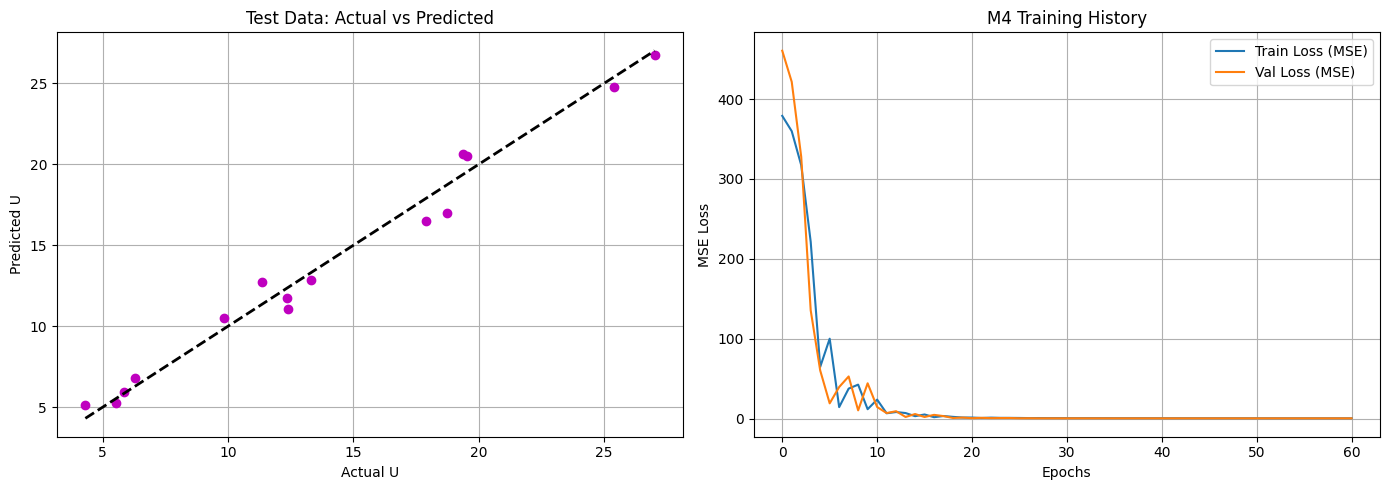

In [6]:
# %% 6. Test the Network (Best Model)
# Evaluate ONLY on Test Set
test_predictions = best_model.predict(X_test_scaled).flatten()

test_mse = mean_squared_error(y_test, test_predictions)
test_mae = mean_absolute_error(y_test, test_predictions)
test_rmse = np.sqrt(test_mse)

print(f'--- Final Evaluation on Test Set ({best_name}) ---')
print(f'Test MSE: {test_mse:.6f}')
print(f'Test MAE: {test_mae:.6f}')
print(f'Test RMSE: {test_rmse:.6f}\n')

# Plot Regression for Actual vs Predicted & Learning Curves
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(y_test, test_predictions, 'mo', markerfacecolor='m')
p_min = min(np.min(y_test), np.min(test_predictions))
p_max = max(np.max(y_test), np.max(test_predictions))
plt.plot([p_min, p_max], [p_min, p_max], 'k--', lw=2)
plt.xlabel('Actual U')
plt.ylabel('Predicted U')
plt.title('Test Data: Actual vs Predicted')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(best_history.history['loss'], label='Train Loss (MSE)')
plt.plot(best_history.history['val_loss'], label='Val Loss (MSE)')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title(f'{best_name} Training History')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


### بخش هفتم: استنتاج رابطه متغیرها

**پاسخ‌های نظری:**
- **الگوهای بیش‌برازش و کم‌برازش:** در تصویر M4 test data x Training history.png، مشاهده می‌شود که خطای Train و Validation هر دو به سرعت کاهش یافته و روی مقادیر بسیار پایینی تثبیت شده‌اند که نشان‌دهنده یک برازش عالی است. اگر خطای Train کاهش می‌یافت اما خطای Validation شروع به بالا رفتن می‌کرد، نشانه Overfitting بود که اقدام اصلاحی آن استفاده از Early Stopping یا کاهش تعداد نورون‌ها است. اگر هر دو خطا بالا می‌ماندند، نشانه Underfitting بود و باید پیچیدگی مدل افزایش می‌یافت.
- **چرا نباید از Test بارها استفاده کرد؟** استفاده مکرر از Test برای تنظیم معماری، آن را تبدیل به یک مجموعه Validation دوم می‌کند و نشت داده رخ می‌دهد. این کار توانایی مجموعه Test برای سنجش عملکرد واقعی مدل روی داده‌های ندیده را از بین می‌برد.
- **ناکافی بودن خطای Training:** کم بودن خطای Training تنها اثبات می‌کند که شبکه توانسته داده‌های دیده شده را حفظ کند، اما لزوماً تضمین نمی‌کند که مدل بتواند روی داده‌های جدید (تعمیم‌پذیری) نیز عملکرد درستی داشته باشد.

**تحلیل عملی:**
- **۱) روند رابطه U با X:** در نمودار پراکنش فایل `Data Exploration.png`، رابطه U با X یک روند کاملاً صعودی و خمیده را نشان می‌دهد. با افزایش مقدار X، مقدار U با شیب فزاینده‌ای بالا می‌رود که نشان‌دهنده یک رابطه غیرخطی قوی است. این رفتار غیرخطی در نمودار `Sweep X` از فایل `Controlled Sweep.png` کاملاً تایید می‌شود؛ جایی که با خنثی کردن اثر سایر متغیرها، منحنی پیش‌بینی شده برای U یک شکل سهمی (تقریباً درجه دوم) به خود می‌گیرد.
- **۲) روند رابطه U با Y:** بر اساس نمودار میانی در `Data Exploration.png`، هیچ روند واضح و قدرتمندی مشابه با متغیر X دیده نمی‌شود و نقاط بسیار پراکنده هستند. این نشان می‌دهد که رابطه Y با U تفاوت اساسی با X دارد و احتمالاً تاثیر Y بر متغیر هدف بسیار ضعیف‌تر از X است، یا الگوی آن به دلیل واریانس بالای سایر متغیرها در نمودار دوبعدی پنهان شده است.
- **۳) رابطه U با Z:** در نگاه اولیه به نمودار پراکنش U در برابر Z در `Data Exploration.png`، نقاط کاملاً پخش شده‌اند و الگوی مستقیمی به چشم نمی‌خورد. با این حال، با بررسی نمودار `Sweep Z` در `Controlled Sweep.png` (که در آن اثر متغیرهای X و Y ثابت نگه داشته شده است)، مشخص می‌شود که Z یک رابطه کاملاً مستقیم و خطی با خروجی U دارد.
- **۴) فرضیه کلی و نقش نویز:** با تجمیع این مشاهدات، فرضیه کلی این است که متغیر هدف U حاصل ترکیب یک تابع غیرخطی (احتمالاً توانی/درجه دوم) از X و یک تابع خطی از Z (و احتمالاً Y) است. پراکندگی و عدم تطابق کامل نقاط در نمودارهای `Data Exploration.png` به دلیل تداخل متغیرها بر روی یکدیگر و وجود نویز ذاتی (Random Noise) در مجموعه داده است. مدل برگزیده (M4) موفق شده این روابط الگوهای زیربنایی را به خوبی یاد بگیرد، اما وجود همین نویز باعث می‌شود پیش‌بینی‌ها کاملاً بی‌نقص نباشند (خطای Test MSE برابر ۰.۸۸۷) و در نمودار `Test Data: Actual vs Predicted` فایل `M4 test data x Training history.png`، انحرافات بسیار جزئی نسبت به خط چین ایده‌آل دیده شود.


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 


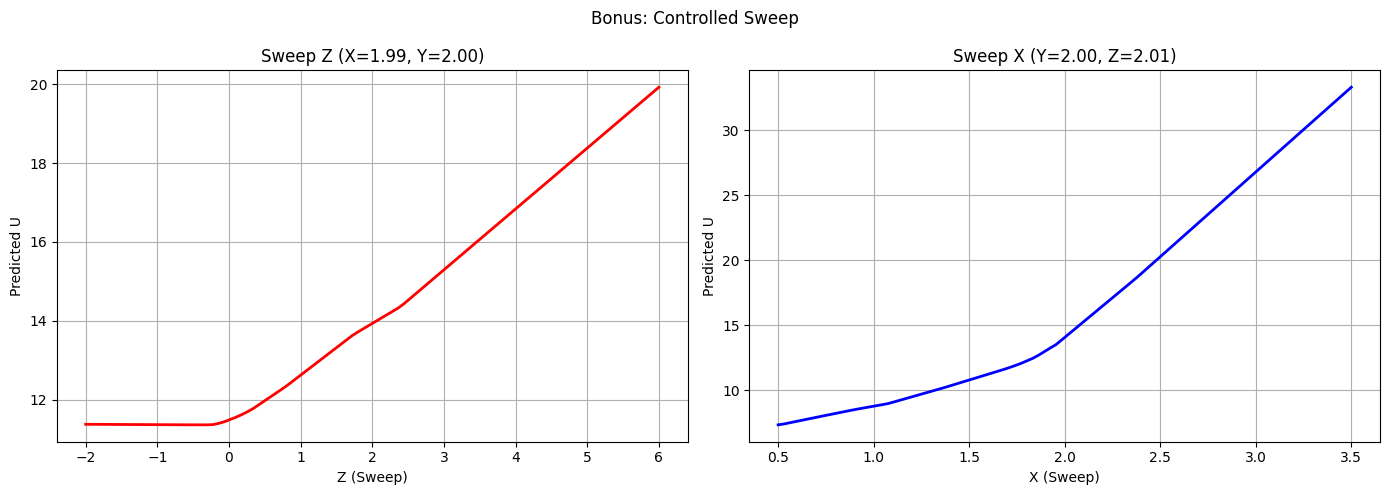

In [8]:
# %% 7. Bonus: Controlled Sweep
# Fix two variables to their mean, sweep the third
mean_x = data['X'].mean()
mean_y = data['Y'].mean()
mean_z = data['Z'].mean()

# Sweep Z (keep X and Y at mean)
z_sweep = np.linspace(-2, 6, 100)
sweep_inputs_z = np.column_stack([np.full(100, mean_x), np.full(100, mean_y), z_sweep])
sweep_inputs_z_scaled = scaler.transform(sweep_inputs_z)
sweep_outputs_z = best_model.predict(sweep_inputs_z_scaled).flatten()

# Sweep X (keep Y and Z at mean)
x_sweep = np.linspace(0.5, 3.5, 100)
sweep_inputs_x = np.column_stack([x_sweep, np.full(100, mean_y), np.full(100, mean_z)])
sweep_inputs_x_scaled = scaler.transform(sweep_inputs_x)
sweep_outputs_x = best_model.predict(sweep_inputs_x_scaled).flatten()

plt.figure(figsize=(14, 5))
plt.suptitle('Bonus: Controlled Sweep')

plt.subplot(1, 2, 1)
plt.plot(z_sweep, sweep_outputs_z, 'r-', lw=2)
plt.xlabel('Z (Sweep)')
plt.ylabel('Predicted U')
plt.title(f'Sweep Z (X={mean_x:.2f}, Y={mean_y:.2f})')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(x_sweep, sweep_outputs_x, 'b-', lw=2)
plt.xlabel('X (Sweep)')
plt.ylabel('Predicted U')
plt.title(f'Sweep X (Y={mean_y:.2f}, Z={mean_z:.2f})')
plt.grid(True)

plt.tight_layout()
plt.show()



### بخش امتیازی: بررسی کنترل شده رابطه

**تحلیل عملی:**
- **۱) مقادیر ثابت و بازه تغییر ورودی‌ها:**
  - برای بررسی اثر Z در فایل `Controlled Sweep.png`، متغیرهای X و Y روی مقدار میانگین خود (به ترتیب ۱.۹۹ و ۲.۰۰) ثابت شده‌اند و متغیر Z در بازه تقریبی ۲- تا ۶ جاروب (Sweep) شده است.
  - برای بررسی اثر X، متغیرهای Y و Z روی مقدار میانگین خود (۲.۰۰ و ۲.۰۱) ثابت شده‌اند و متغیر X در بازه ۰.۵ تا ۳.۵ تغییر داده شده است.
- **۲) پیش‌بینی و نمودار خروجی:** مدل M4 با دریافت این داده‌های مصنوعی کنترل‌شده، خروجی‌های هدف را پیش‌بینی کرده که در قالب دو نمودار خطی در `Controlled Sweep.png` رسم شده‌اند.
- **۳) تحلیل روند و پیشنهاد رابطه:**
  - نمودار سمت چپ (`Sweep Z`) با تولید یک خط کاملاً راست، اثبات می‌کند که رابطه متغیر Z با خروجی U **کاملاً خطی** است.
  - نمودار سمت راست (`Sweep X`) با نمایش یک منحنی با تقعر رو به بالا، ثابت می‌کند که رابطه X با خروجی U **غیرخطی (احتمالاً چندجمله‌ای درجه دوم)** است.
  - **محدودیت‌های نتیجه‌گیری:** از آنجایی که این تحلیل بر اساس پیش‌بینی‌های شبکه عصبی (که یک تقریب‌زن بر اساس داده‌های موجود است) انجام شده، این روابط تنها در محدوده داده‌های آموزش (Interpolation) معتبر هستند و نمی‌توان با اطمینان گفت که مدل برای مقادیر فراتر از این بازه‌ها (Extrapolation) همین الگو را با دقت حفظ کند.
